In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tensorflow.examples.tutorials.mnist import input_data
mnist = input_data.read_data_sets('./mnist/data/', one_hot=True)

Successfully downloaded train-images-idx3-ubyte.gz 9912422 bytes.
Extracting ./mnist/data/train-images-idx3-ubyte.gz
Successfully downloaded train-labels-idx1-ubyte.gz 28881 bytes.
Extracting ./mnist/data/train-labels-idx1-ubyte.gz
Successfully downloaded t10k-images-idx3-ubyte.gz 1648877 bytes.
Extracting ./mnist/data/t10k-images-idx3-ubyte.gz
Successfully downloaded t10k-labels-idx1-ubyte.gz 4542 bytes.
Extracting ./mnist/data/t10k-labels-idx1-ubyte.gz


In [3]:
learning_rate = 0.01
training_epoch = 20
batch_size = 100
n_hidden = 256
n_input = 28 * 28

In [4]:
X = tf.placeholder(tf.float32, [None, n_input])

W_encode = tf.Variable(tf.random_normal([n_input, n_hidden]))
b_encode = tf.Variable(tf.random_normal([n_hidden]))
encoder = tf.nn.sigmoid(tf.add(tf.matmul(X, W_encode), b_encode))

W_decode = tf.Variable(tf.random_normal([n_hidden, n_input]))
b_decode = tf.Variable(tf.random_normal([n_input]))
decoder = tf.nn.sigmoid(tf.add(tf.matmul(encoder, W_decode), b_decode))

In [5]:
cost = tf.reduce_mean(tf.pow(X - decoder, 2))
optimizer = tf.train.RMSPropOptimizer(learning_rate).minimize(cost)

In [6]:
sess = tf.Session()
sess.run(tf.global_variables_initializer())

total_batch = int(mnist.train.num_examples / batch_size)

for epoch in range(training_epoch):
    total_cost = 0
    
    for i in range(total_batch):
        batch_xs, batch_ys = mnist.train.next_batch(batch_size)
        
        _, cost_val = sess.run([optimizer, cost], feed_dict={X: batch_xs})
        
        total_cost += cost_val
    
    print('Epoch:', '%04d' % (epoch + 1), 'Avg. Cost =', '{:.3f}'.format(total_cost / total_batch))

print('Training Completed !')

Epoch: 0001 Avg. Cost = 0.192
Epoch: 0002 Avg. Cost = 0.058
Epoch: 0003 Avg. Cost = 0.050
Epoch: 0004 Avg. Cost = 0.045
Epoch: 0005 Avg. Cost = 0.043
Epoch: 0006 Avg. Cost = 0.040
Epoch: 0007 Avg. Cost = 0.039
Epoch: 0008 Avg. Cost = 0.038
Epoch: 0009 Avg. Cost = 0.037
Epoch: 0010 Avg. Cost = 0.036
Epoch: 0011 Avg. Cost = 0.036
Epoch: 0012 Avg. Cost = 0.036
Epoch: 0013 Avg. Cost = 0.035
Epoch: 0014 Avg. Cost = 0.035
Epoch: 0015 Avg. Cost = 0.035
Epoch: 0016 Avg. Cost = 0.032
Epoch: 0017 Avg. Cost = 0.031
Epoch: 0018 Avg. Cost = 0.031
Epoch: 0019 Avg. Cost = 0.031
Epoch: 0020 Avg. Cost = 0.031
Training Completed !


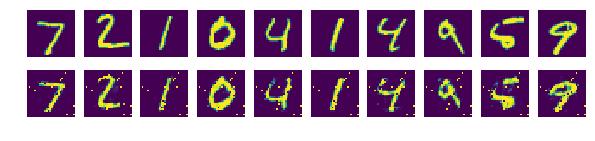

In [7]:
sample_size = 10

samples = sess.run(decoder, feed_dict={X: mnist.test.images[:sample_size]})

fig, ax = plt.subplots(2, sample_size, figsize=(sample_size, 2))

for i in range(sample_size):
    ax[0][i].set_axis_off()
    ax[1][i].set_axis_off()
    ax[0][i].imshow(np.reshape(mnist.test.images[i], (28, 28)))
    ax[1][i].imshow(np.reshape(samples[i], (28, 28)))

plt.show()